# Notebook 04: So sánh Mô hình

Notebook này đọc kết quả từ CSV (không huấn luyện lại mô hình) và tạo các bảng, hình so sánh.

> **Lưu ý:** Mọi số liệu lấy từ file CSV do `train.py` sinh ra. Không điền tay.

In [1]:
import sys
import os
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from config import TABLES_DIR, FIGURES_DIR, METRIC_COLUMNS, MODEL_NAMES
from evaluation import (
    df_to_markdown, plot_confusion_matrices, plot_roc_pr_curves,
    plot_metrics_by_fold, plot_model_comparison, plot_repeated_distribution,
    plot_sensitivity
)

# Đọc các file kết quả
metrics_df = pd.read_csv(TABLES_DIR / 'metrics_per_fold.csv', encoding='utf-8')
summary_df = pd.read_csv(TABLES_DIR / 'metrics_summary.csv', encoding='utf-8')
oof_df = pd.read_csv(TABLES_DIR / 'oof_predictions.csv', encoding='utf-8')
paired_df = pd.read_csv(TABLES_DIR / 'paired_differences.csv', encoding='utf-8')
repeated_df = pd.read_csv(TABLES_DIR / 'metrics_repeated.csv', encoding='utf-8')
best_params_df = pd.read_csv(TABLES_DIR / 'best_params.csv', encoding='utf-8')

print('Các thí nghiệm trong metrics_per_fold.csv:', metrics_df['experiment'].unique().tolist())
print(f'Tổng số dòng: {len(metrics_df)}')

Các thí nghiệm trong metrics_per_fold.csv: ['E0_main', 'S1a_drop_course', 'S1b_course_min_freq5', 'S2_class_weight_balanced', 'E1_nested', 'S3_plus_anxiety_panic']
Tổng số dòng: 150


## 1. Kết quả chính E0 — mean ± std

In [2]:
e0_summary = summary_df[summary_df['experiment'] == 'E0_main'][['model'] + 
    [f'{m}_mean' for m in METRIC_COLUMNS] + [f'{m}_std' for m in METRIC_COLUMNS]]
e0_summary = e0_summary.set_index('model').reindex(MODEL_NAMES).reset_index()
print('Bảng kết quả E0 (mean ± std):')
print(df_to_markdown(e0_summary))

Bảng kết quả E0 (mean ± std):
| model              |   accuracy_mean |   precision_yes_mean |   recall_yes_mean |   f1_yes_mean |   roc_auc_mean |   pr_auc_mean |   accuracy_std |   precision_yes_std |   recall_yes_std |   f1_yes_std |   roc_auc_std |   pr_auc_std |
|:-------------------|----------------:|---------------------:|------------------:|--------------:|---------------:|--------------:|---------------:|--------------------:|-----------------:|-------------:|--------------:|-------------:|
| Dummy              |           0.653 |                0.000 |             0.000 |         0.000 |          0.500 |         0.347 |          0.007 |               0.000 |            0.000 |        0.000 |         0.000 |        0.007 |
| LogisticRegression |           0.812 |                0.914 |             0.543 |         0.666 |          0.806 |         0.814 |          0.074 |               0.192 |            0.120 |        0.111 |         0.117 |        0.094 |
| DecisionTree       |

In [3]:
# Điểm từng fold E0
e0_folds = metrics_df[metrics_df['experiment'] == 'E0_main'][['model','fold','f1_yes','recall_yes','accuracy','roc_auc','pr_auc']]
print('Điểm từng fold (E0):')
print(df_to_markdown(e0_folds))

Điểm từng fold (E0):
| model              |   fold |   f1_yes |   recall_yes |   accuracy |   roc_auc |   pr_auc |
|:-------------------|-------:|---------:|-------------:|-----------:|----------:|---------:|
| Dummy              |      0 |    0.000 |        0.000 |      0.667 |     0.500 |    0.333 |
| Dummy              |      1 |    0.000 |        0.000 |      0.650 |     0.500 |    0.350 |
| Dummy              |      2 |    0.000 |        0.000 |      0.650 |     0.500 |    0.350 |
| Dummy              |      3 |    0.000 |        0.000 |      0.650 |     0.500 |    0.350 |
| Dummy              |      4 |    0.000 |        0.000 |      0.650 |     0.500 |    0.350 |
| LogisticRegression |      0 |    0.600 |        0.429 |      0.810 |     0.959 |    0.937 |
| LogisticRegression |      1 |    0.571 |        0.571 |      0.700 |     0.659 |    0.704 |
| LogisticRegression |      2 |    0.833 |        0.714 |      0.900 |     0.868 |    0.880 |
| LogisticRegression |      3 |    0.72

## 2. Hình — Ma trận nhầm lẫn

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\01_confusion_matrices_e0.png


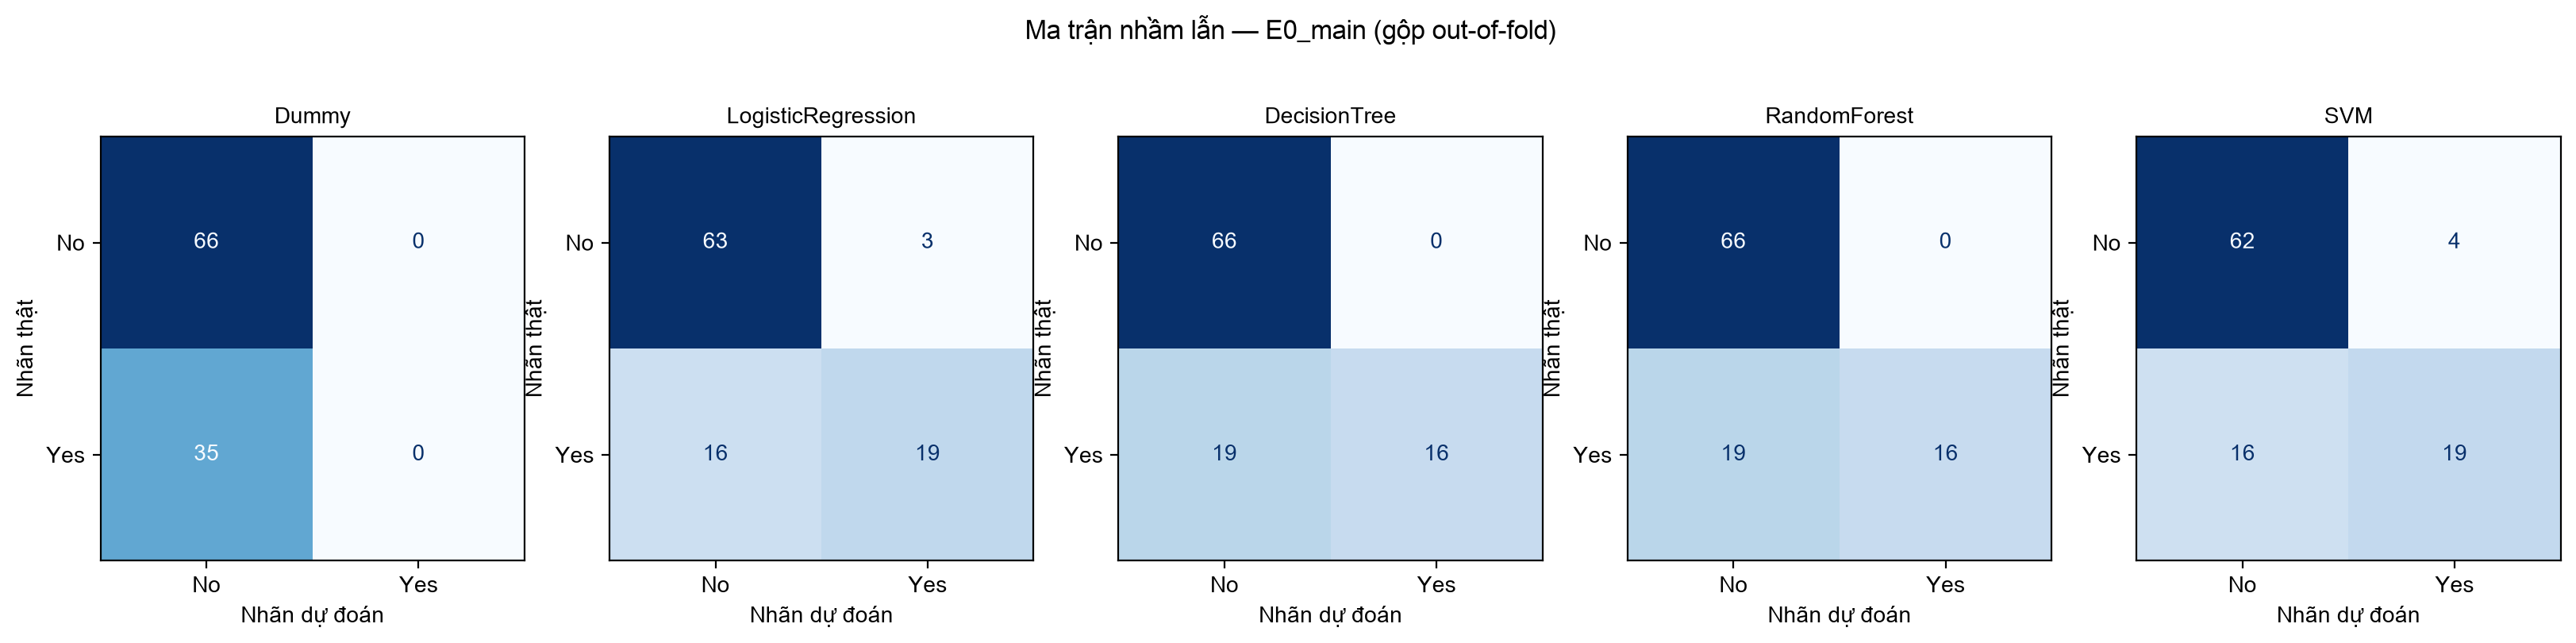

In [4]:
fig_path = plot_confusion_matrices(oof_df, experiment='E0_main', models=MODEL_NAMES)
print(f'Đã lưu: {fig_path}')
from IPython.display import Image
Image(str(fig_path))

## 3. Hình — Đường cong ROC và PR

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\02_roc_pr_oof_e0.png


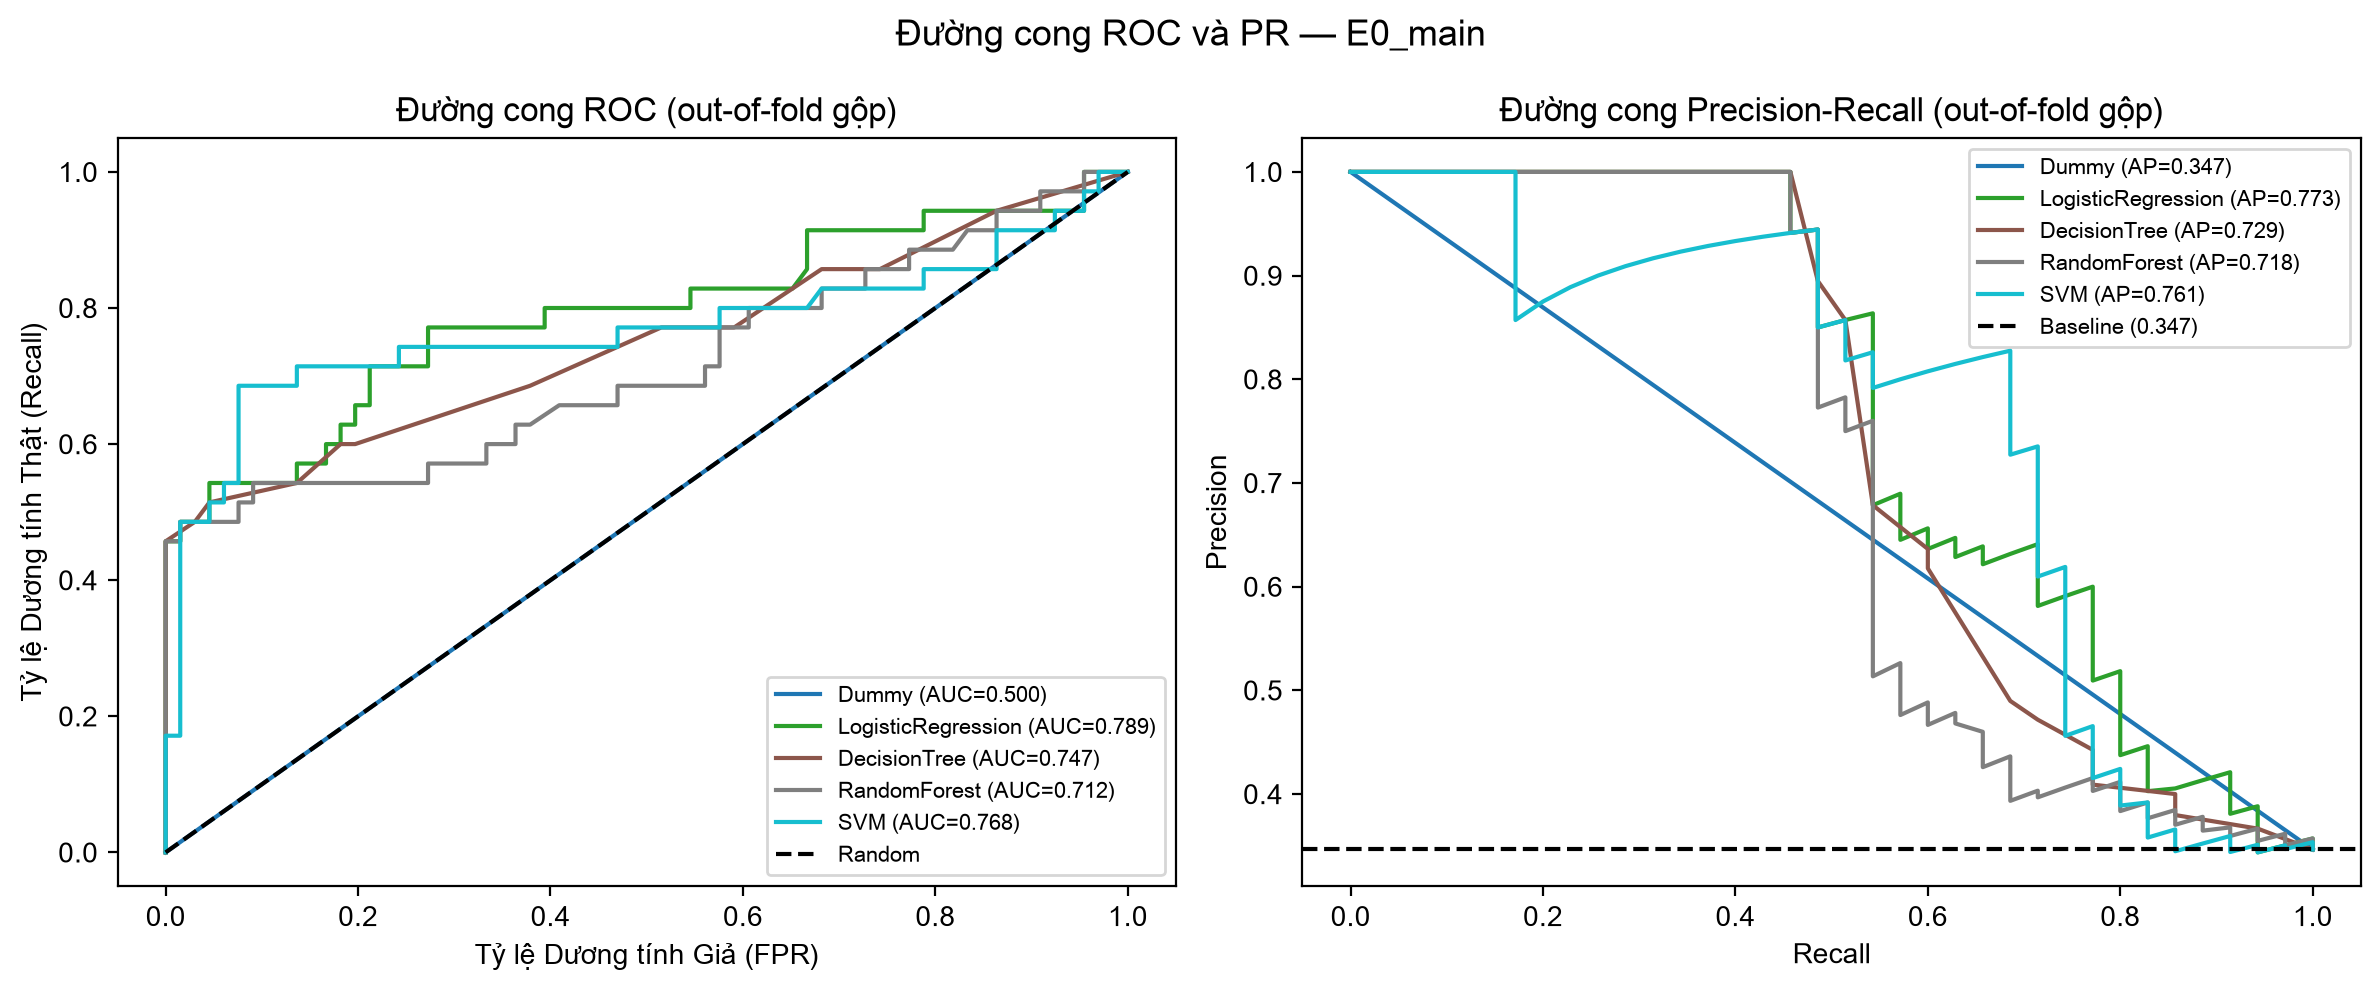

In [5]:
fig_path = plot_roc_pr_curves(oof_df, experiment='E0_main')
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

## 4. Hình — Metric theo fold

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\03_metrics_by_fold_e0.png


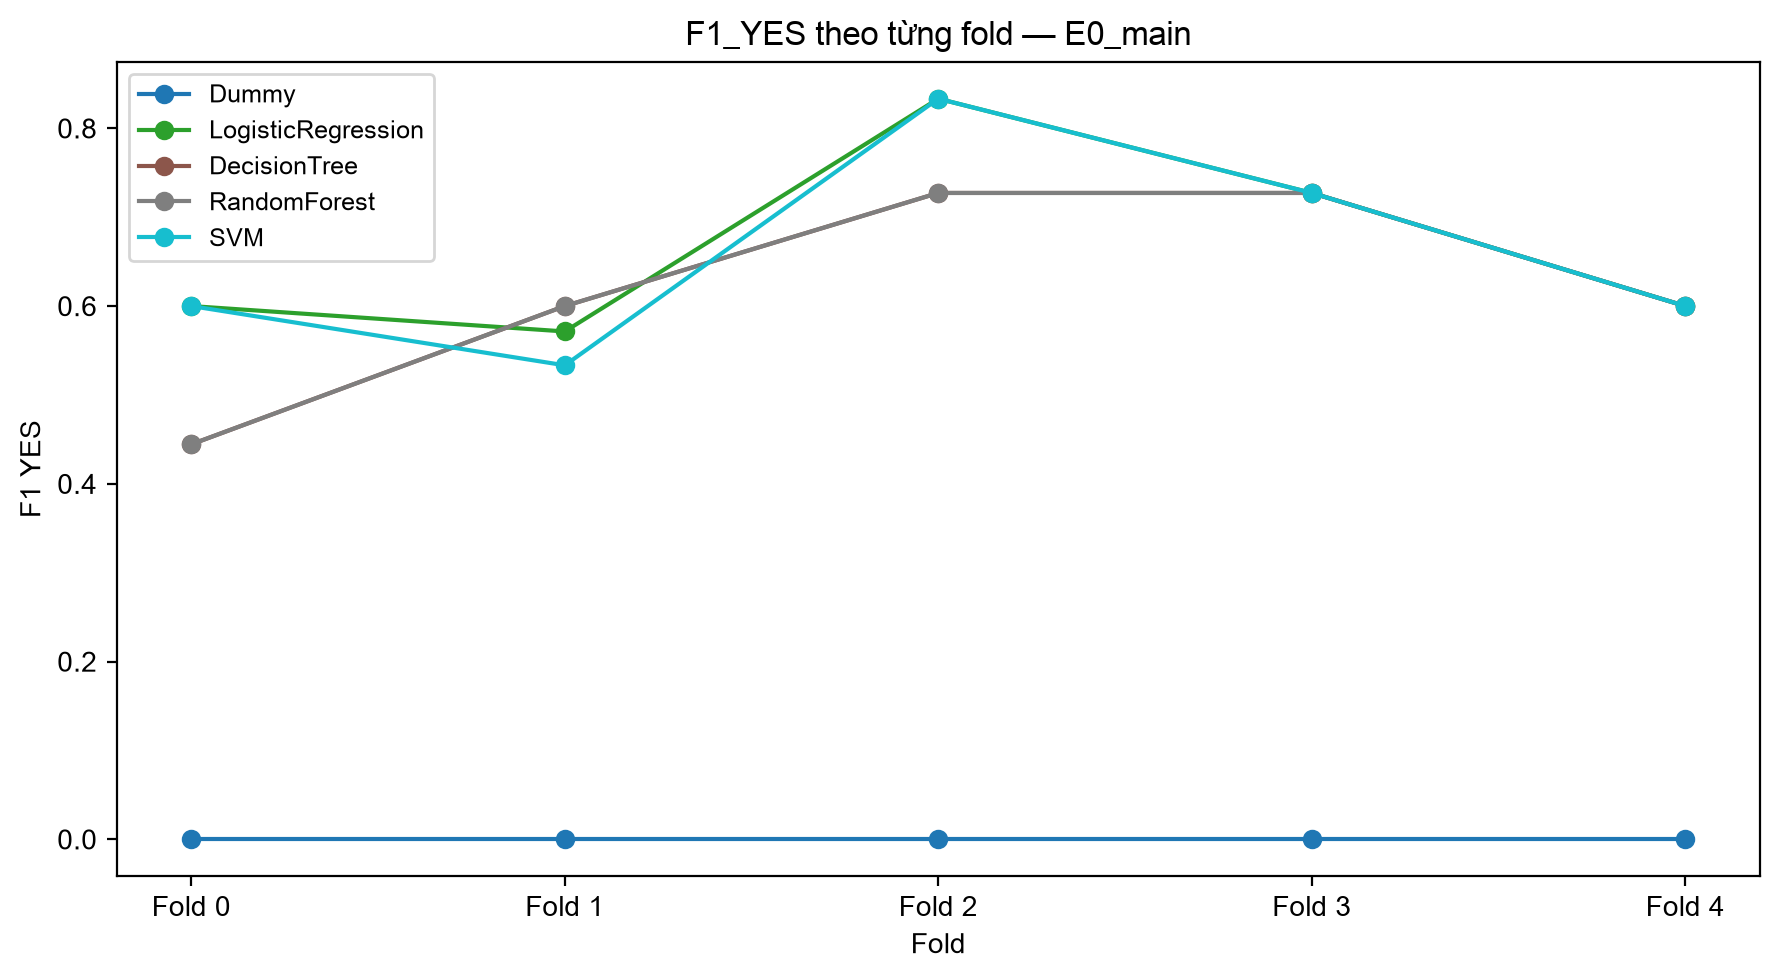

In [6]:
fig_path = plot_metrics_by_fold(metrics_df, experiment='E0_main', metric='f1_yes')
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

## 5. Hình — So sánh E0 và E1

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\04_model_comparison_e0_e1.png


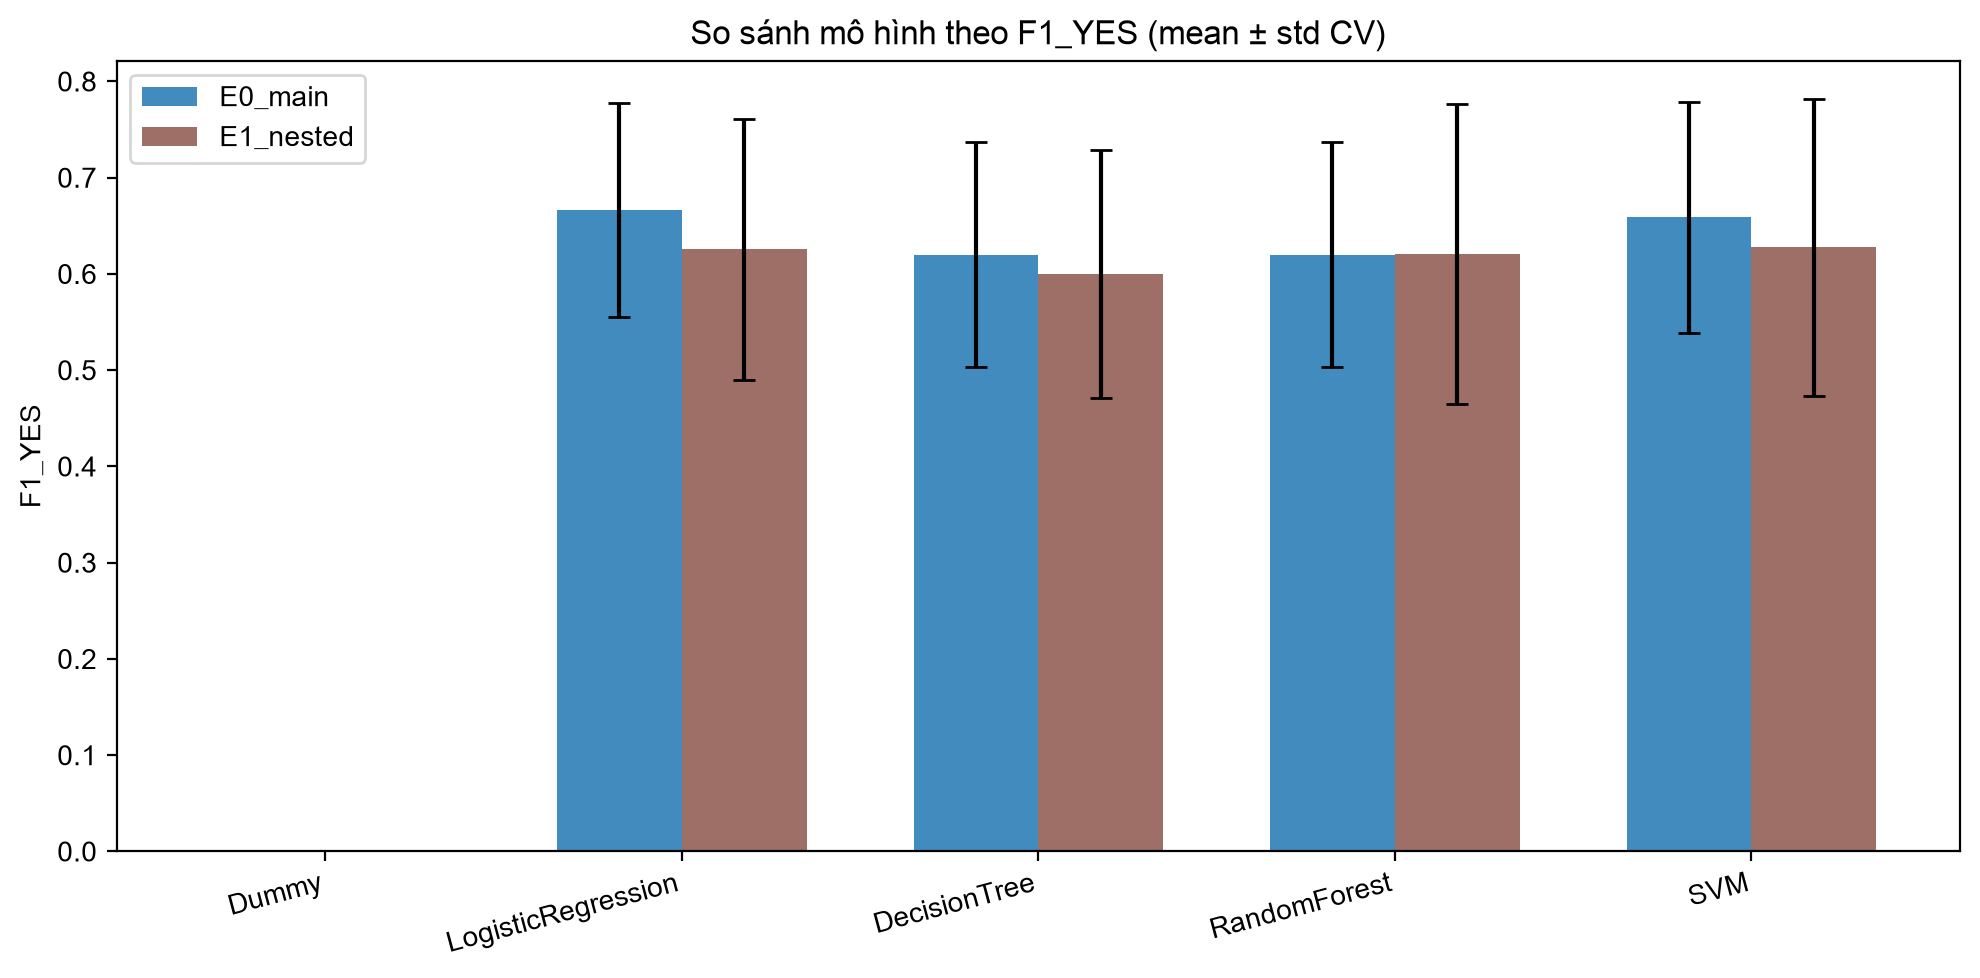

In [7]:
fig_path = plot_model_comparison(summary_df, experiments=['E0_main', 'E1_nested'])
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

## 6. E1 — Nested CV và tham số được chọn

In [8]:
e1_summary = summary_df[summary_df['experiment'] == 'E1_nested'][['model','f1_yes_mean','f1_yes_std','recall_yes_mean','roc_auc_mean']]
print('Kết quả E1 Nested CV (mean ± std):')
print(df_to_markdown(e1_summary))

print('\nTham số được chọn ở mỗi outer fold:')
print(df_to_markdown(best_params_df))

print('\n⚠️ Lưu ý: Mỗi inner-validation chỉ có ~9 ca Yes → lựa chọn tham số bất ổn.')

Kết quả E1 Nested CV (mean ± std):
| model              |   f1_yes_mean |   f1_yes_std |   recall_yes_mean |   roc_auc_mean |
|:-------------------|--------------:|-------------:|------------------:|---------------:|
| DecisionTree       |         0.600 |        0.129 |             0.486 |          0.697 |
| Dummy              |         0.000 |        0.000 |             0.000 |          0.500 |
| LogisticRegression |         0.626 |        0.136 |             0.571 |          0.817 |
| RandomForest       |         0.620 |        0.156 |             0.543 |          0.756 |
| SVM                |         0.628 |        0.154 |             0.514 |          0.780 |

Tham số được chọn ở mỗi outer fold:
| model              |   outer_fold | best_params                                          |   inner_best_score |
|:-------------------|-------------:|:-----------------------------------------------------|-------------------:|
| LogisticRegression |            0 | {"clf__C": 1}            

## 7. E2 — Repeated CV

In [9]:
fig_path = plot_repeated_distribution(repeated_df, metric='f1_yes')
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

print('\n⚠️ Lưu ý: Các fold trong E2 không độc lập; std chỉ mang tính tham khảo.')

D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\src\evaluation.py:456: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\05_repeated_cv_distribution.png

⚠️ Lưu ý: Các fold trong E2 không độc lập; std chỉ mang tính tham khảo.


## 8. Phân tích độ nhạy S1–S3

In [10]:
fig_path = plot_sensitivity(summary_df)
print(f'Đã lưu: {fig_path}')
Image(str(fig_path))

print('\n⚠️ S3 (thêm Anxiety + Panic attack) là phụ, có chồng lấn khái niệm với trầm cảm;')
print('   không dùng để so sánh hoặc kết luận mô hình tốt hơn.')

Đã lưu: D:\Documents\HOC TAP (D)\TRI TUE NHAN TAO\Mental-Student-Health-\results\ml\figures\06_sensitivity.png

⚠️ S3 (thêm Anxiety + Panic attack) là phụ, có chồng lấn khái niệm với trầm cảm;
   không dùng để so sánh hoặc kết luận mô hình tốt hơn.


## 9. So sánh cặp (paired_differences)

In [11]:
e0_diffs = paired_df[
    (paired_df['experiment'] == 'E0_main') & 
    (paired_df['metric'] == 'f1_yes')
][['model','reference','mean_diff','std_diff','n_folds_better']]
print('So sánh cặp F1(Yes) — E0:')
print(df_to_markdown(e0_diffs))

print('\nQuy tắc kết luận: chỉ nói "X tốt hơn Y" khi mean_diff > std_diff VÀ n_folds_better >= 4/5.')

So sánh cặp F1(Yes) — E0:
| model              | reference          |   mean_diff |   std_diff |   n_folds_better |
|:-------------------|:-------------------|------------:|-----------:|-----------------:|
| LogisticRegression | Dummy              |       0.666 |      0.111 |                5 |
| DecisionTree       | Dummy              |       0.620 |      0.117 |                5 |
| RandomForest       | Dummy              |       0.620 |      0.117 |                5 |
| SVM                | Dummy              |       0.659 |      0.120 |                5 |
| Dummy              | LogisticRegression |      -0.666 |      0.111 |                0 |
| DecisionTree       | LogisticRegression |      -0.047 |      0.080 |                1 |
| RandomForest       | LogisticRegression |      -0.047 |      0.080 |                1 |
| SVM                | LogisticRegression |      -0.008 |      0.017 |                0 |

Quy tắc kết luận: chỉ nói "X tốt hơn Y" khi mean_diff > std_diff VÀ n_fol